### 0. Préparation

 importe les bibliothèques et fixe les paramètres du projet (seuil 0,3, graine aléatoire, une couleur fixe par puce).

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold"})

# --- Paramètres du projet (tous les choix sont ici) ---
FICHIER = "data.csv"
SEUIL = 0.3            # seuil de sensibilisation en kUA/L
SEED = 42              # reproductibilité
PUCES = ["ISAC_V1", "ISAC_V2", "ALEX"]
COUL_PUCE = {"ISAC_V1": "#2a78d6", "ISAC_V2": "#eb6834", "ALEX": "#1baf7a"}   # une couleur fixe par puce
PALETTE8 = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLEU, GRIS, ROUGE = "#2a78d6", "#c9ced6", "#e34948"

# PARTIE 1 – Description des variables

### 1. Chargement du fichier

lit le CSV (séparateur `;`, décimale `,`), lit en texte les 5 colonnes à codes multiples (`1,3` = deux traitements) et sépare les 15 colonnes cliniques des 241 colonnes d'IgE.

In [ ]:
MULTI = ["Treatment_of_rhinitis", "Treatment_of_athsma", "Age_of_onsets",
         "General_cofactors", "Treatment_of_atopic_dematitis"]          # colonnes à codes multiples
df = pd.read_csv(FICHIER, sep=";", decimal=",", encoding="utf-8-sig", low_memory=False,
                 dtype={c: str for c in MULTI})

COL_CLIN = list(df.columns[:15])    # les 15 colonnes sur le patient
COL_IGE = list(df.columns[15:])     # les 241 colonnes d'allergènes

print(f"Nombre de lignes   : {df.shape[0]}  → une ligne = un patient")
print(f"Nombre de colonnes : {df.shape[1]}  → {len(COL_CLIN)} colonnes cliniques + {len(COL_IGE)} colonnes d'IgE")
print(f"Patient_ID unique pour chaque ligne : {df['Patient_ID'].is_unique}")
df.head()

Nombre de lignes   : 4271  → une ligne = un patient
Nombre de colonnes : 256  → 15 colonnes cliniques + 241 colonnes d'IgE
Patient_ID unique pour chaque ligne : True


,Patient_ID,Chip_Type,Age,Gender,Blood_Month_sample,French_Residence_Department,French_Region,Rural_or_urban_area,Sensitization,Treatment_of_rhinitis,Treatment_of_athsma,Age_of_onsets,Skin_Symptoms,General_cofactors,Treatment_of_atopic_dematitis,Act_d_1,Act_d_2,Act_d_5,Act_d_8,Aln_g_1,Alt_a_1,Alt_a_6,Amb_a_1,Ana_o_2,Ani_s_1,...,Jug_r_pollen,Jun_a,Len_c,Lit_s,Loc_m,Lol_p_1,Lol_spp.,Lup_a,Mac_i_2S_Albumin,Mac_inte,Mal_d_2,Mal_d_3,Mala_s_11,Mala_s_5,Mala_s_6,Man_i,Mel_g,Mes_a_1_RUO,Mor_r,Mus_a,Myt_e,Ole_e_7_RUO,Ori_v,Ory_c_1,Ory_c_2
0,FHB0001,ISAC_V1,21.0,1.0,11.0,deptY,regionB,9,1,9,9,9,9,0,9,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,FHB0002,ISAC_V1,45.0,0.0,12.0,deptY,regionB,9,1,9,9,9,9,0,9,0.0,0.0,0.0,6.0,19.32,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,FHB0003,ISAC_V1,18.0,1.0,1.0,deptY,regionB,9,0,2,9,0,9,5,9,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,FHB0004,ISAC_V1,19.0,0.0,1.0,deptY,regionB,9,1,9,9,9,9,0,9,0.0,0.0,0.0,0.0,13.42,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,FHB0005,ISAC_V1,28.0,0.0,1.0,deptY,regionB,9,1,9,9,9,9,0,9,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Interprétation**

- Une ligne = un patient : **4 271 patients**, **256 colonnes** (15 cliniques + 241 IgE). `Patient_ID` est unique.
- Les colonnes de traitement, d'âge d'apparition et de cofacteurs sont lues en **texte**, sinon `1,3` deviendrait le nombre 1,3.

### 1.1 Types des colonnes

**Ce que fait ce code :** affiche le type lu par Python pour chaque colonne clinique et un exemple de valeur.

,type lu,exemple de valeur
Patient_ID,str,FHB0001
Chip_Type,str,ISAC_V1
Age,float64,21.0
Gender,float64,1.0
Blood_Month_sample,float64,11.0
French_Residence_Department,str,deptY
French_Region,str,regionB
Rural_or_urban_area,int64,9
Sensitization,int64,1
Treatment_of_rhinitis,str,9


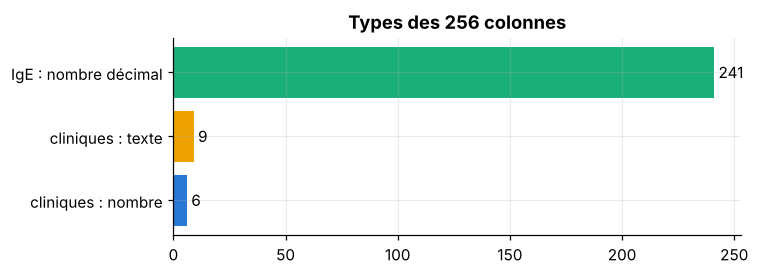

In [ ]:
# Les 15 colonnes cliniques et le type lu par Python
types = pd.DataFrame({"type lu": df[COL_CLIN].dtypes.astype(str),
                      "exemple de valeur": [df[c].dropna().iloc[0] for c in COL_CLIN]})
display(types)

fig, ax = plt.subplots(figsize=(7, 2.6))
t = pd.Series({"cliniques : nombre": int((df[COL_CLIN].dtypes != object).sum() - (df[COL_CLIN].dtypes.astype(str) == "str").sum()),
               "cliniques : texte": int((df[COL_CLIN].dtypes.astype(str).isin(["object", "str"])).sum()),
               "IgE : nombre décimal": len(COL_IGE)})
ax.barh(t.index, t.values, color=[BLEU, "#eda100", "#1baf7a"])
for i, v in enumerate(t.values): ax.text(v + 2, i, str(v), va="center")
ax.set_title("Types des 256 colonnes"); plt.tight_layout(); plt.show()

**Interprétation**

- Les 241 colonnes d'IgE sont toutes des nombres décimaux.
- Parmi les colonnes cliniques, celles lues en texte sont soit des identifiants/catégories (patient, puce, département, région), soit des colonnes à codes multiples.

### 2. Signification de chaque colonne clinique

**Ce que fait ce code :** écrit le dictionnaire des 15 colonnes (sens, type, codes) d'après le dictionnaire officiel, et résume pour chacune les cases vides et le code 9 (« non renseigné »).

In [ ]:
DICO = {
 "Patient_ID": ("Identifiant anonyme du patient", "identifiant", {}),
 "Chip_Type": ("Puce utilisée pour l'analyse de sang", "catégorielle",
               {"ISAC_V1": "puce ISAC version 1 (112 protéines)", "ISAC_V2": "puce ISAC E112i (112 protéines)",
                "ALEX": "puce ALEX² (223 protéines)"}),
 "Age": ("Âge au moment de la prise de sang (années)", "numérique", {}),
 "Gender": ("Sexe", "binaire", {"0": "féminin", "1": "masculin"}),
 "Blood_Month_sample": ("Mois de la prise de sang", "catégorielle (1 à 12)", {}),
 "French_Residence_Department": ("Département de résidence (anonymisé)", "catégorielle", {}),
 "French_Region": ("Région de résidence (anonymisée)", "catégorielle", {}),
 "Rural_or_urban_area": ("Lieu de vie", "binaire", {"0": "rural", "1": "urbain", "9": "non renseigné"}),
 "Sensitization": ("Sensibilisé à au moins une protéine (au moins un IgE ≥ 0,3)", "binaire",
                   {"0": "non sensibilisé", "1": "sensibilisé"}),
 "Treatment_of_rhinitis": ("Traitement de la rhinite (nez) → présence et gravité", "ordinale",
     {"0": "aucun", "1": "antihistaminique local", "2": "antihistaminique par voie générale",
      "3": "antihistaminique + corticoïde local", "4": "corticoïde par voie générale", "9": "non renseigné"}),
 "Treatment_of_athsma": ("Traitement de l'asthme (échelle GINA) → présence et gravité", "ordinale",
     {"0": "aucun", "1": "bronchodilatateur à la demande", "2": "corticoïde inhalé faible dose",
      "3": "corticoïde + bronchodilatateur, faible dose", "4": "idem, dose moyenne ou forte",
      "5": "forte dose ou corticoïde au long cours", "6": "biothérapie anti-IL5", "7": "biothérapie anti-IL4/13",
      "8": "non-répondeur aux biothérapies", "10": "antileucotriène (traitement léger)", "9": "non renseigné"}),
 "Age_of_onsets": ("Âge d'apparition de l'allergie alimentaire", "ordinale",
     {"0": "pas d'allergie alimentaire", "1": "avant 6 mois", "2": "6 mois à 2 ans", "3": "2 à 3 ans",
      "4": "3 à 10 ans", "5": "10 à 20 ans", "6": "après 20 ans", "9": "non renseigné"}),
 "Skin_Symptoms": ("Symptômes de peau (urticaire) lors d'une anaphylaxie alimentaire", "binaire",
     {"0": "non", "1": "oui", "9": "sans objet (dictionnaire) / non renseigné"}),
 "General_cofactors": ("Cofacteurs : situations qui aggravent une réaction", "catégorielle (plusieurs possibles)",
     {"0": "aucun connu", "1": "effort / sport", "2": "anti-inflammatoires (AINS)", "3": "alcool",
      "4": "moisissures (logement)", "5": "acariens (literie)", "6": "chat", "7": "chien", "8": "cheval",
      "10": "rongeurs (code suspect, voir partie 3)", "11": "mucoviscidose", "12": "anti-acides (IPP)",
      "9": "non renseigné"}),
 "Treatment_of_atopic_dematitis": ("Traitement de l'eczéma (dermatite atopique) → présence et gravité", "ordinale",
     {"0": "aucun", "1": "crèmes émollientes", "2": "dermocorticoïdes", "3": "tacrolimus", "4": "ciclosporine",
      "5": "dupilumab", "6": "upadacitinib", "7": "baricitinib", "9": "non renseigné"}),
}

def codes_de(x):
    """'1,3' → ['1', '3'] ; case vide → []."""
    if pd.isna(x): return []
    return [str(int(float(v))) for v in str(x).replace(" ", "").split(",") if v != ""]

resume = []
for col in COL_CLIN:
    sens, typ, codes = DICO[col]
    s = df[col]
    vides = int(s.isna().sum())
    n9 = int(s.apply(lambda x: "9" in codes_de(x)).sum()) if "9" in codes else 0
    if typ == "numérique" or col == "Blood_Month_sample":
        valeurs = f"{s.min():.0f} à {s.max():.0f}"
    else:
        valeurs = f"{s.nunique()} valeurs différentes"
    resume.append([col, sens, typ, valeurs, vides, n9, round((vides + n9) / len(df) * 100, 1)])
resume = pd.DataFrame(resume, columns=["colonne", "signification", "type", "valeurs", "cases vides", "code 9", "% manquant"])
resume

,colonne,signification,type,valeurs,cases vides,code 9,% manquant
0,Patient_ID,Identifiant anonyme du patient,identifiant,4271 valeurs différentes,0,0,0.0
1,Chip_Type,Puce utilisée pour l'analyse de sang,catégorielle,3 valeurs différentes,0,0,0.0
2,Age,Âge au moment de la prise de sang (années),numérique,0 à 102,61,0,1.4
3,Gender,Sexe,binaire,2 valeurs différentes,62,0,1.5
4,Blood_Month_sample,Mois de la prise de sang,catégorielle (1 à 12),1 à 12,125,0,2.9
5,French_Residence_Department,Département de résidence (anonymisé),catégorielle,82 valeurs différentes,0,0,0.0
6,French_Region,Région de résidence (anonymisée),catégorielle,15 valeurs différentes,0,0,0.0
7,Rural_or_urban_area,Lieu de vie,binaire,3 valeurs différentes,0,2980,69.8
8,Sensitization,"Sensibilisé à au moins une protéine (au moins un IgE ≥ 0,3)",binaire,2 valeurs différentes,0,0,0.0
9,Treatment_of_rhinitis,Traitement de la rhinite (nez) → présence et gravité,ordinale,9 valeurs différentes,0,2958,69.3


**Interprétation**

- Les colonnes qui décrivent **qui est le patient** (puce, âge, sexe, région) sont presque complètes (moins de 3 % de cases vides).
- Les colonnes **cliniques** (traitements, lieu de vie) sont manquantes pour **60 à 70 %** des patients, mais ce manquant est caché sous le **code 9**, pas dans des cases vides.
- Les trois traitements (asthme, rhinite, eczéma) sont ordinaux : plus le code est élevé, plus le traitement est lourd, donc plus la maladie est grave (sauf le code 10 de l'asthme, un traitement léger).

# 1.3 – Signification des valeurs et effectifs

Pour chaque variable codée : chaque code, sa signification, le nombre de patients et un graphique. Une case à plusieurs codes (`1,3`) compte pour **chacun** de ses codes.

### 3. Fonctions de comptage des codes

**Ce que fait ce code :** définit deux fonctions : un tableau « code → signification → effectif » et un graphique en barres (gris = code 9 ou case vide).

In [ ]:
def tableau_codes(col):
    listes = df[col].apply(codes_de) if col in MULTI else df[col].apply(lambda x: [] if pd.isna(x) else [str(int(x)) if isinstance(x, float) else str(x)])
    eclate = listes.explode().dropna()
    n = eclate.value_counts()
    multi = listes[listes.apply(len) > 1].explode().value_counts()
    t = pd.DataFrame({"code": n.index, "patients": n.values})
    t["signification"] = t["code"].map(DICO[col][2]).fillna("?")
    t["dont dans une case à plusieurs codes"] = t["code"].map(multi).fillna(0).astype(int)
    t["% des patients"] = (t["patients"] / len(df) * 100).round(1)
    vides = int((listes.apply(len) == 0).sum())
    if vides:
        t.loc[len(t)] = ["vide", vides, "case vide", 0, round(vides / len(df) * 100, 1)]
    ordre = t["code"].map(lambda c: float(c) if c.isdigit() else 99)
    return t.assign(_o=ordre).sort_values("_o").drop(columns="_o").reset_index(drop=True)

def graphe_codes(col, ax):
    t = tableau_codes(col)
    lab = [f"{c} – {s}" for c, s in zip(t["code"], t["signification"])]
    coul = [GRIS if c in ("9", "vide") else BLEU for c in t["code"]]
    ax.barh(lab, t["% des patients"], color=coul)
    for i, v in enumerate(t["% des patients"]): ax.text(v + 0.8, i, f"{v:.0f} %", va="center", fontsize=8)
    ax.invert_yaxis(); ax.set_xlim(0, 110); ax.tick_params(axis="y", labelsize=8)
    ax.set_title(f"{col}\n{DICO[col][0]}", fontsize=9)

### 3.1 Variables oui/non et puce

**Ce que fait ce code :** affiche le tableau et le graphique des valeurs pour la puce, le sexe, la sensibilisation, le lieu de vie et les symptômes cutanés.


■ Chip_Type – Puce utilisée pour l'analyse de sang


,code,patients,signification,dont dans une case à plusieurs codes,% des patients
0,ISAC_V1,2351,puce ISAC version 1 (112 protéines),0,55.0
1,ALEX,1139,puce ALEX² (223 protéines),0,26.7
2,ISAC_V2,781,puce ISAC E112i (112 protéines),0,18.3



■ Gender – Sexe


,code,patients,signification,dont dans une case à plusieurs codes,% des patients
0,0,2070,féminin,0,48.5
1,1,2139,masculin,0,50.1
2,vide,62,case vide,0,1.5



■ Sensitization – Sensibilisé à au moins une protéine (au moins un IgE ≥ 0,3)


,code,patients,signification,dont dans une case à plusieurs codes,% des patients
0,0,692,non sensibilisé,0,16.2
1,1,3579,sensibilisé,0,83.8



■ Rural_or_urban_area – Lieu de vie


,code,patients,signification,dont dans une case à plusieurs codes,% des patients
0,0,325,rural,0,7.6
1,1,966,urbain,0,22.6
2,9,2980,non renseigné,0,69.8



■ Skin_Symptoms – Symptômes de peau (urticaire) lors d'une anaphylaxie alimentaire


,code,patients,signification,dont dans une case à plusieurs codes,% des patients
0,0,686,non,0,16.1
1,1,1140,oui,0,26.7
2,9,2445,sans objet (dictionnaire) / non renseigné,0,57.2


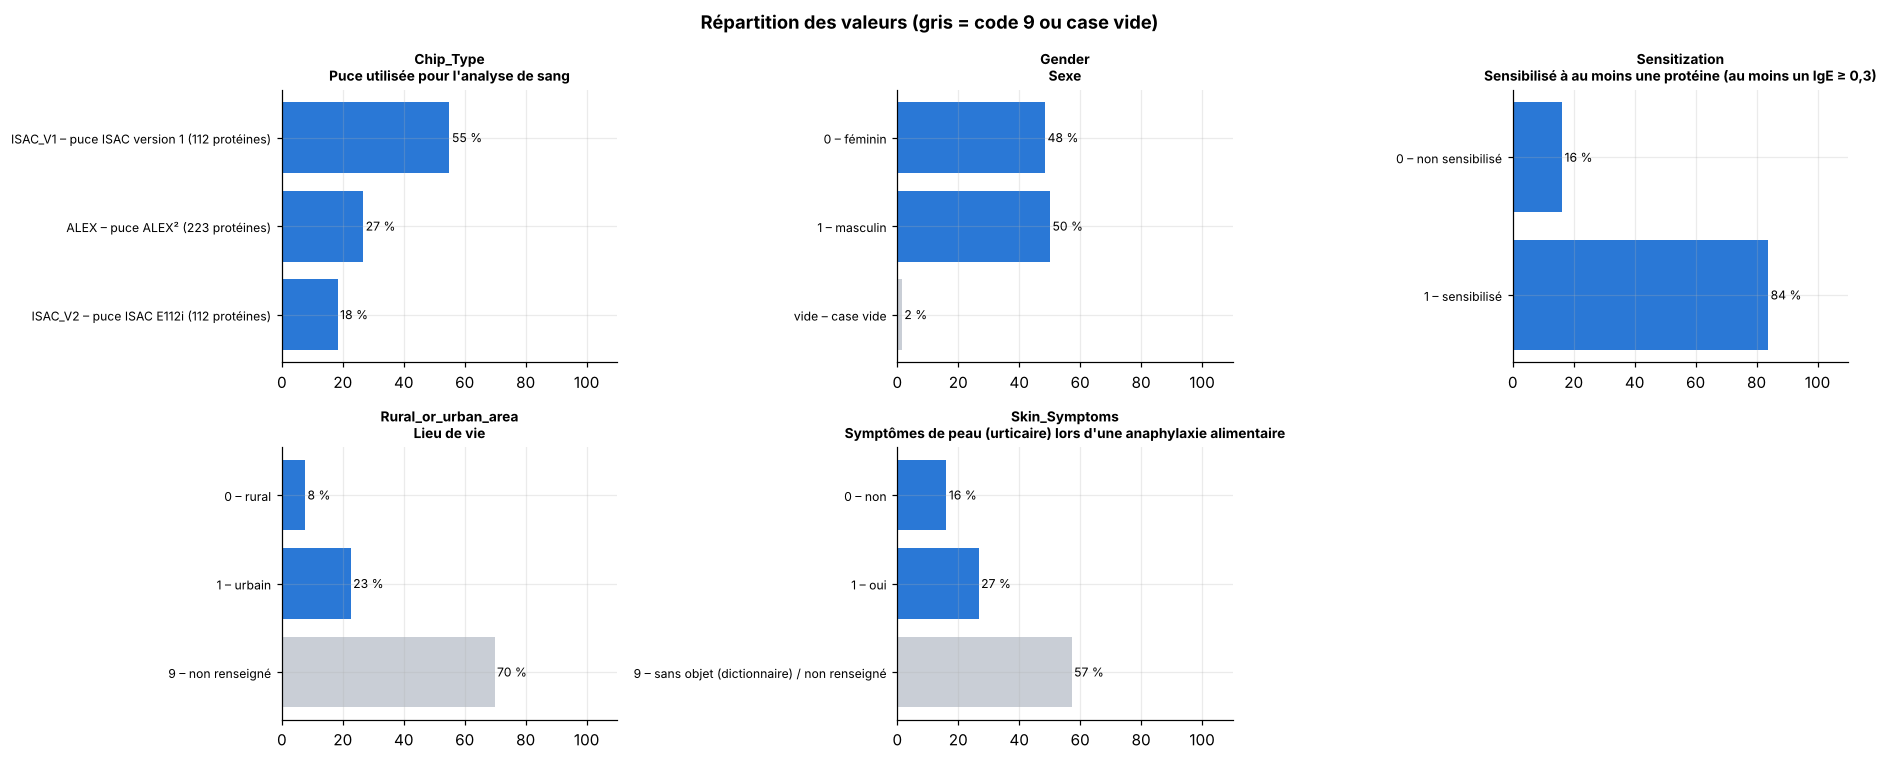

In [ ]:
for col in ["Chip_Type", "Gender", "Sensitization", "Rural_or_urban_area", "Skin_Symptoms"]:
    print(f"\n■ {col} – {DICO[col][0]}")
    display(tableau_codes(col))

fig, axes = plt.subplots(2, 3, figsize=(17, 7))
for ax, col in zip(axes.ravel(), ["Chip_Type", "Gender", "Sensitization", "Rural_or_urban_area", "Skin_Symptoms"]):
    graphe_codes(col, ax)
axes.ravel()[-1].axis("off")
plt.suptitle("Répartition des valeurs (gris = code 9 ou case vide)", fontweight="bold")
plt.tight_layout(); plt.show()

**Interprétation**

- **Puce** : 55 % des patients sont testés avec ISAC_V1, 27 % avec ALEX, 18 % avec ISAC_V2.
- **Sensibilisation** : 84 % des patients sont sensibilisés à au moins une protéine ; 692 ne le sont à aucune.
- **Lieu de vie** : connu pour seulement 30 % des patients (1 291) ; parmi eux, environ 3 sur 4 vivent en milieu urbain.
- **Sexe** : équilibré (48 % de filles, 50 % de garçons).

### 3.1 bis Que veut dire le 9 de `Skin_Symptoms` ?

**Ce que fait ce code :** croise `Skin_Symptoms` avec l'âge d'apparition de l'allergie alimentaire pour voir ce que le code 9 recouvre en pratique.

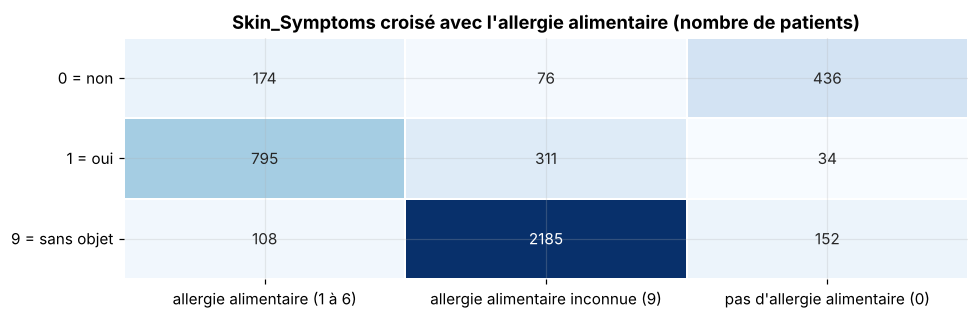

In [ ]:
aa = df["Age_of_onsets"].apply(codes_de).str[0].map(
    lambda c: "allergie alimentaire inconnue (9)" if c == "9" else "pas d'allergie alimentaire (0)" if c == "0" else "allergie alimentaire (1 à 6)")
t = pd.crosstab(df["Skin_Symptoms"].map({0: "0 = non", 1: "1 = oui", 9: "9 = sans objet"}), aa)
fig, ax = plt.subplots(figsize=(9, 3))
sns.heatmap(t, annot=True, fmt="d", cmap="Blues", cbar=False, linewidths=1, ax=ax)
ax.set_title("Skin_Symptoms croisé avec l'allergie alimentaire (nombre de patients)"); ax.set_ylabel(""); ax.set_xlabel("")
ax.tick_params(axis="y", rotation=0)
plt.tight_layout(); plt.show()

**Interprétation**

- `Skin_Symptoms = 1` (symptômes cutanés) va presque toujours avec une allergie alimentaire : c'est le symptôme cutané de l'anaphylaxie alimentaire.
- Le dictionnaire dit 9 = « sans objet », mais **89 % des patients codés 9 ont aussi l'allergie alimentaire inconnue** : en pratique, le 9 mélange « sans objet » et « non renseigné ». Il sera traité à part.

### 3.2 Les traitements

**Ce que fait ce code :** affiche les effectifs de chaque niveau de traitement pour l'asthme, la rhinite et l'eczéma.


■ Treatment_of_athsma – Traitement de l'asthme (échelle GINA) → présence et gravité


,code,patients,signification,dont dans une case à plusieurs codes,% des patients
0,0,897,aucun,0,21.0
1,1,120,bronchodilatateur à la demande,9,2.8
2,2,88,corticoïde inhalé faible dose,10,2.1
3,3,130,"corticoïde + bronchodilatateur, faible dose",2,3.0
4,4,147,"idem, dose moyenne ou forte",3,3.4
5,5,106,forte dose ou corticoïde au long cours,5,2.5
6,6,12,biothérapie anti-IL5,4,0.3
7,7,13,biothérapie anti-IL4/13,6,0.3
8,8,2,non-répondeur aux biothérapies,1,0.0
9,9,2771,non renseigné,0,64.9



■ Treatment_of_rhinitis – Traitement de la rhinite (nez) → présence et gravité


,code,patients,signification,dont dans une case à plusieurs codes,% des patients
0,0,883,aucun,0,20.7
1,1,92,antihistaminique local,7,2.2
2,2,224,antihistaminique par voie générale,2,5.2
3,3,113,antihistaminique + corticoïde local,7,2.6
4,4,9,corticoïde par voie générale,0,0.2
5,9,2958,non renseigné,0,69.3



■ Treatment_of_atopic_dematitis – Traitement de l'eczéma (dermatite atopique) → présence et gravité


,code,patients,signification,dont dans une case à plusieurs codes,% des patients
0,0,1294,aucun,0,30.3
1,1,61,crèmes émollientes,8,1.4
2,2,130,dermocorticoïdes,8,3.0
3,3,9,tacrolimus,0,0.2
4,4,11,ciclosporine,0,0.3
5,5,84,dupilumab,0,2.0
6,7,1,baricitinib,0,0.0
7,9,2689,non renseigné,0,63.0


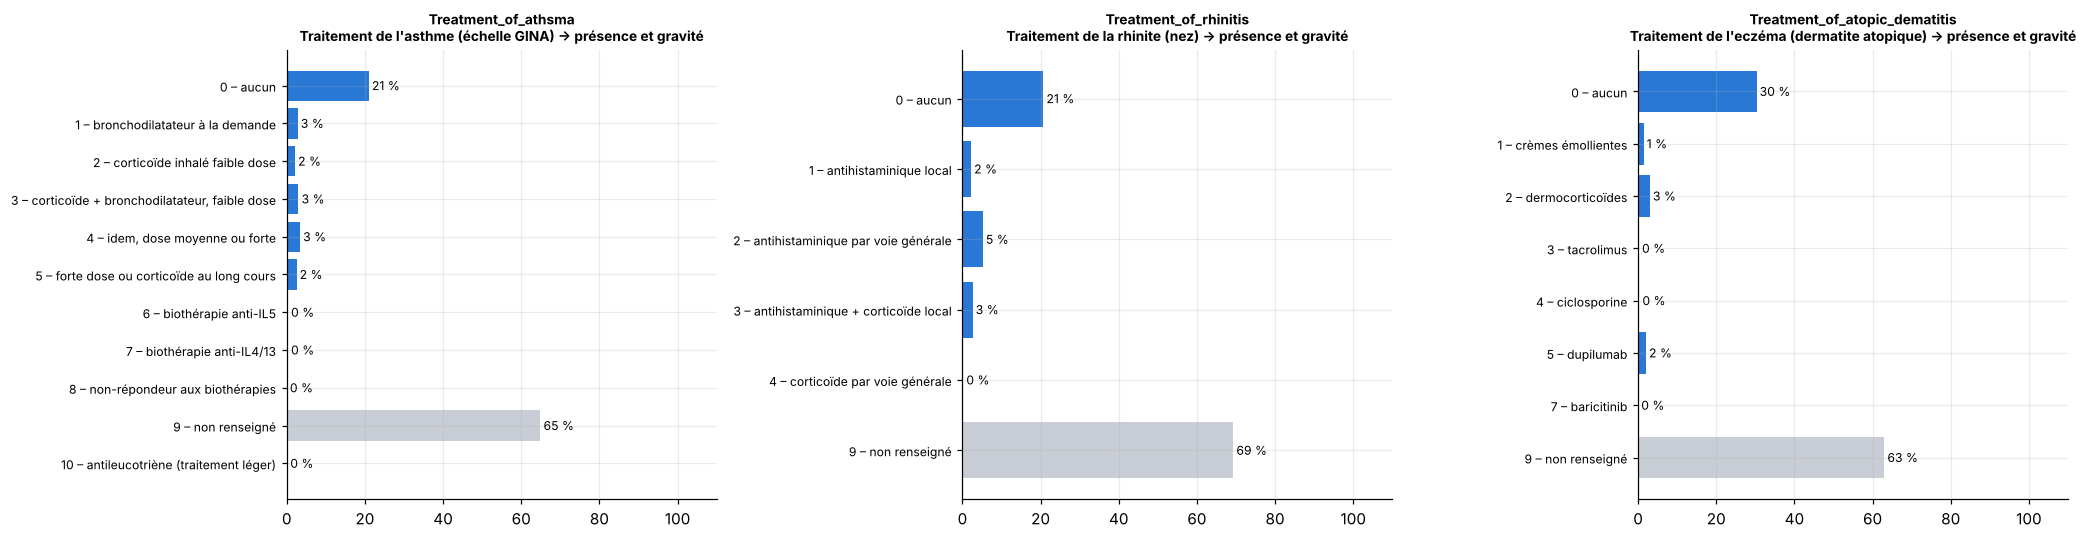

In [ ]:
for col in ["Treatment_of_athsma", "Treatment_of_rhinitis", "Treatment_of_atopic_dematitis"]:
    print(f"\n■ {col} – {DICO[col][0]}")
    display(tableau_codes(col))

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, col in zip(axes, ["Treatment_of_athsma", "Treatment_of_rhinitis", "Treatment_of_atopic_dematitis"]):
    graphe_codes(col, ax)
plt.tight_layout(); plt.show()

**Interprétation**

- **Asthme** : 897 patients sans traitement, environ 500 avec un traitement léger à modéré (codes 1 à 4), environ 130 sous traitement lourd (codes 5 à 8, très peu aux codes 6, 7, 8).
- **Rhinite** : 883 sans traitement, environ 440 traités ; le code 4 (corticoïde général) est très rare (9 patients).
- Le code 9 « non renseigné » concerne 65 % (asthme) à 69 % (rhinite) des patients : les analyses de sévérité porteront sur 1 300 à 1 600 patients seulement.
- Quelques cases contiennent deux traitements : il faudra choisir une règle (par exemple garder le plus lourd).

### 3.3 Allergie alimentaire et cofacteurs

**Ce que fait ce code :** affiche les effectifs de l'âge d'apparition de l'allergie alimentaire et des cofacteurs, et vérifie si le code 10 des cofacteurs est cohérent.


■ Age_of_onsets – Âge d'apparition de l'allergie alimentaire


,code,patients,signification,dont dans une case à plusieurs codes,% des patients
0,0,622,pas d'allergie alimentaire,0,14.6
1,1,91,avant 6 mois,0,2.1
2,2,259,6 mois à 2 ans,1,6.1
3,3,135,2 à 3 ans,1,3.2
4,4,296,3 à 10 ans,0,6.9
5,5,147,10 à 20 ans,0,3.4
6,6,150,après 20 ans,0,3.5
7,9,2572,non renseigné,0,60.2



■ General_cofactors – Cofacteurs : situations qui aggravent une réaction


,code,patients,signification,dont dans une case à plusieurs codes,% des patients
0,0,3010,aucun connu,0,70.5
1,1,142,effort / sport,13,3.3
2,2,9,anti-inflammatoires (AINS),5,0.2
3,3,18,alcool,7,0.4
4,4,36,moisissures (logement),14,0.8
5,5,63,acariens (literie),10,1.5
6,6,70,chat,26,1.6
7,7,57,chien,30,1.3
8,8,4,cheval,3,0.1
9,10,925,"rongeurs (code suspect, voir partie 3)",7,21.7


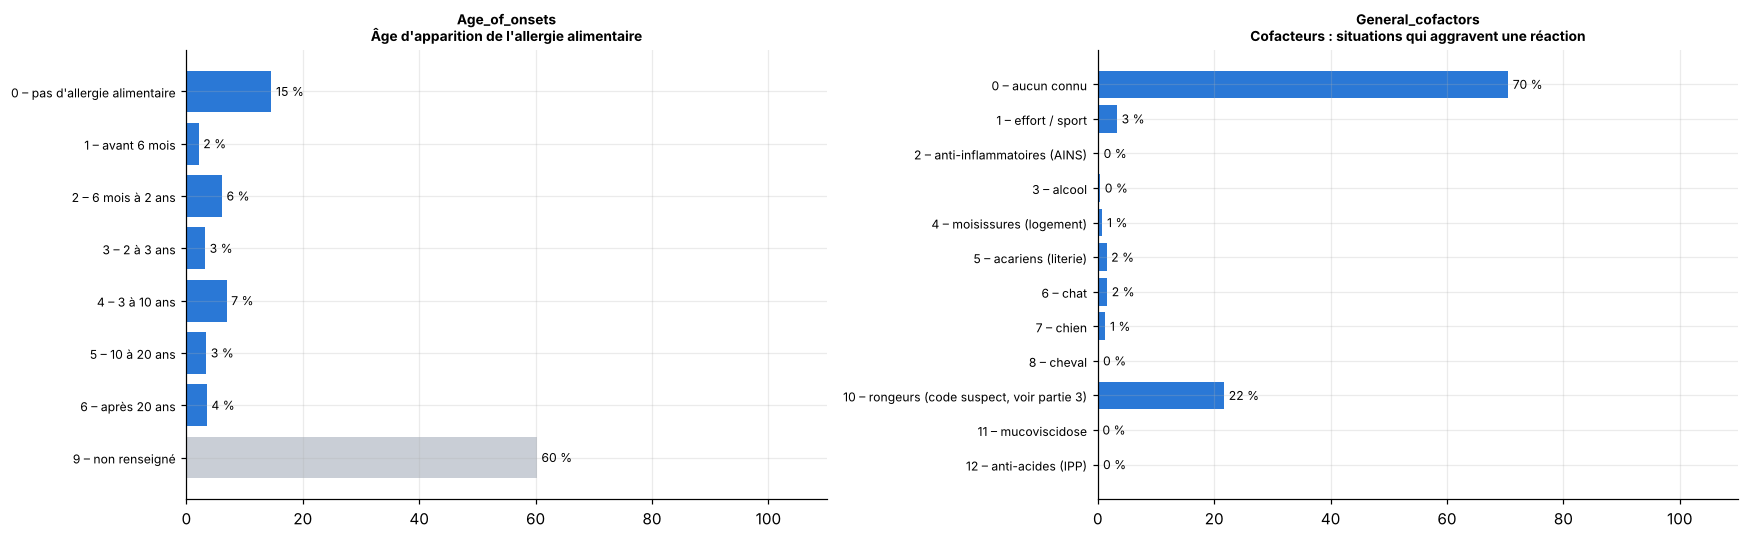

Patients avec le cofacteur 10 : 925, dont 889 avec l'asthme inconnu.
→ Le code 10 (« rongeurs ») apparaît surtout dans les dossiers incomplets : il signifie probablement « inconnu ». À faire confirmer.


In [ ]:
for col in ["Age_of_onsets", "General_cofactors"]:
    print(f"\n■ {col} – {DICO[col][0]}")
    display(tableau_codes(col))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, col in zip(axes, ["Age_of_onsets", "General_cofactors"]):
    graphe_codes(col, ax)
plt.tight_layout(); plt.show()

cof10 = df["General_cofactors"].apply(codes_de).apply(lambda l: "10" in l)
asthme_inconnu = df["Treatment_of_athsma"].apply(codes_de).apply(lambda l: "9" in l)
print(f"Patients avec le cofacteur 10 : {cof10.sum()}, dont {(cof10 & asthme_inconnu).sum()} avec l'asthme inconnu.")
print("→ Le code 10 (« rongeurs ») apparaît surtout dans les dossiers incomplets : il signifie probablement « inconnu ». À faire confirmer.")

**Interprétation**

- **Âge d'apparition** : 622 patients sans allergie alimentaire, environ 1 080 avec une allergie alimentaire, la plus fréquente apparaissant entre 6 mois et 2 ans ou entre 3 et 10 ans ; 60 % sont non renseignés.
- **Cofacteurs** : la grande majorité des patients n'en a aucun connu ; les plus cités sont l'effort (142), le chien (57) et le chat (70).
- **Code 10 suspect** : 925 patients l'ont, dont 889 avec l'asthme inconnu. Il apparaît dans les dossiers incomplets : probablement un code « inconnu », **à faire confirmer** par les référentes du défi.

### 3.4 Variables sans code : âge, mois, région, département

**Ce que fait ce code :** trace l'âge, le mois de prise de sang, les patients par région (couleur = puce) et par département.

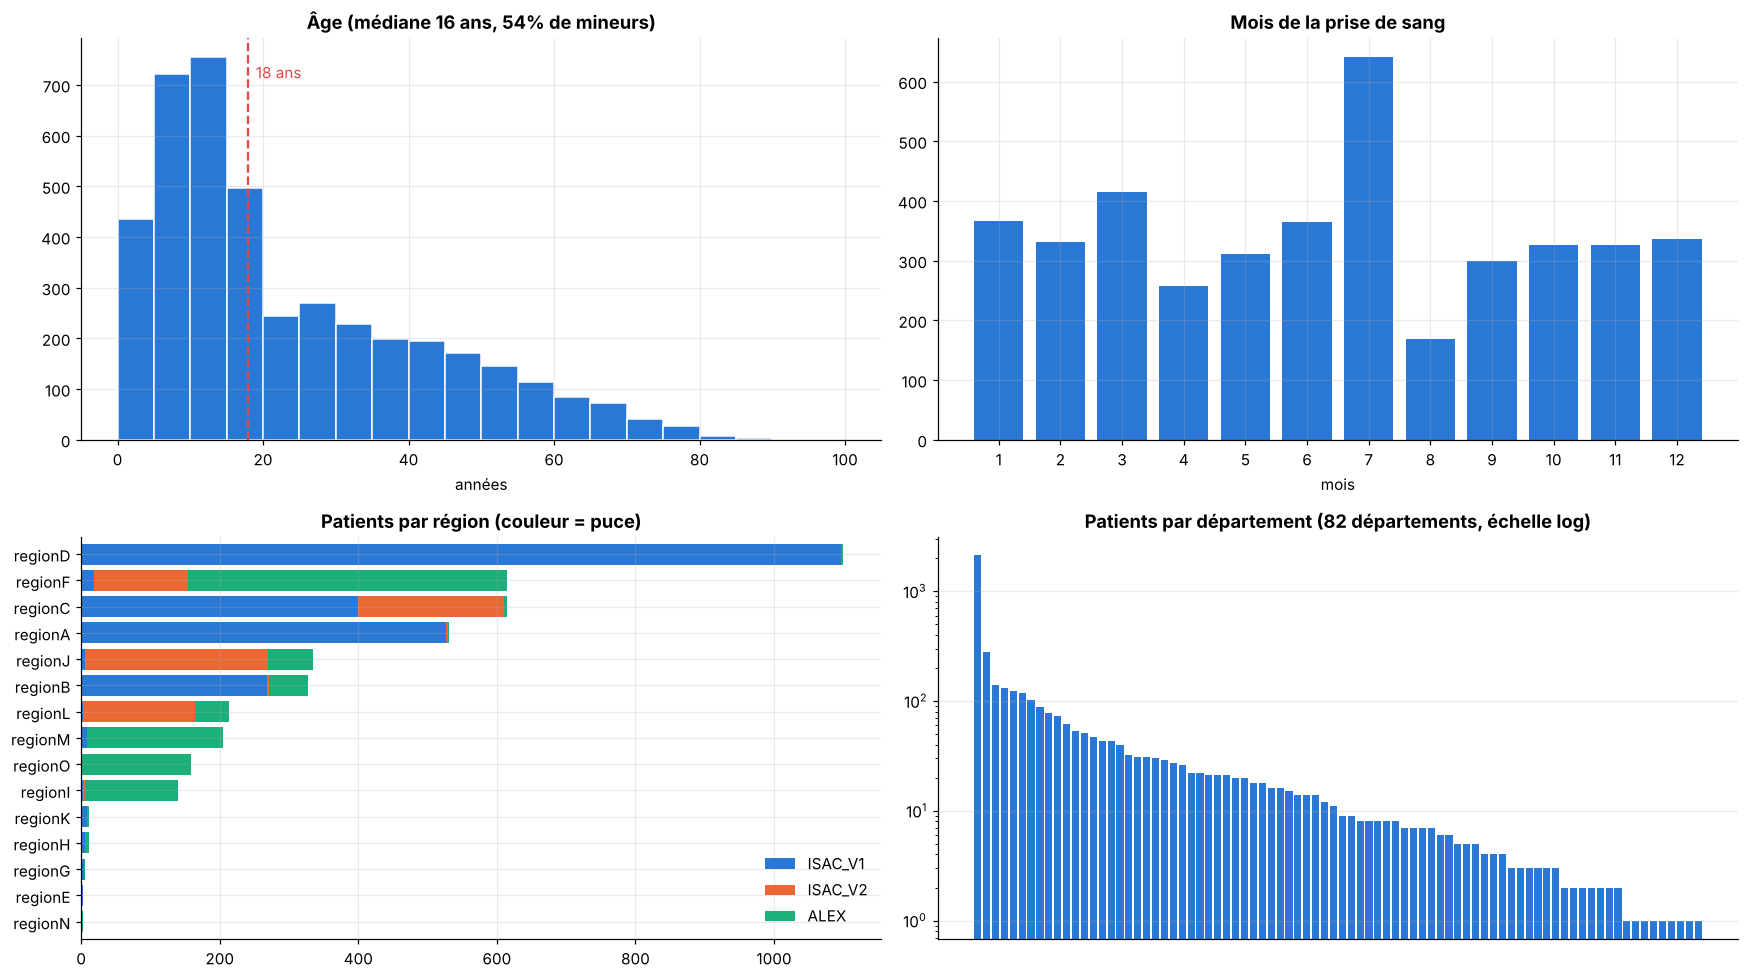

Rappel : pour l'âge et le mois, 9 est une vraie valeur (9 ans, septembre), pas un code « non renseigné ».


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 9))
age = df["Age"].dropna()
axes[0, 0].hist(age, bins=range(0, 105, 5), color=BLEU, edgecolor="white")
axes[0, 0].axvline(18, color=ROUGE, ls="--"); axes[0, 0].text(19, axes[0, 0].get_ylim()[1] * 0.9, "18 ans", color=ROUGE)
axes[0, 0].set_title(f"Âge (médiane {age.median():.0f} ans, {(age < 18).mean():.0%} de mineurs)"); axes[0, 0].set_xlabel("années")

m = df["Blood_Month_sample"].value_counts().sort_index()
axes[0, 1].bar(m.index.astype(int), m.values, color=BLEU)
axes[0, 1].set_xticks(range(1, 13)); axes[0, 1].set_title("Mois de la prise de sang"); axes[0, 1].set_xlabel("mois")

reg = pd.crosstab(df["French_Region"], df["Chip_Type"])[PUCES]
reg = reg.loc[reg.sum(axis=1).sort_values().index]
reg.plot(kind="barh", stacked=True, ax=axes[1, 0], color=[COUL_PUCE[p] for p in PUCES], width=0.8)
axes[1, 0].set_title("Patients par région (couleur = puce)"); axes[1, 0].set_ylabel(""); axes[1, 0].legend(frameon=False)

dep = df["French_Residence_Department"].value_counts()
axes[1, 1].bar(range(len(dep)), dep.values, color=BLEU); axes[1, 1].set_yscale("log"); axes[1, 1].set_xticks([])
axes[1, 1].set_title(f"Patients par département ({len(dep)} départements, échelle log)")
plt.tight_layout(); plt.show()
print("Rappel : pour l'âge et le mois, 9 est une vraie valeur (9 ans, septembre), pas un code « non renseigné ».")

**Interprétation**

- Plus de la moitié des patients sont des **enfants** (âge médian 16 ans, 53 % de mineurs) : population hospitalière, pas représentative de toute la France.
- Chaque région utilise presque une seule puce : comparer des régions revient à comparer des puces et des hôpitaux.
- 15 régions et 82 départements anonymisés ; 5 régions ont moins de 15 patients.

# 1.4 – Les 241 colonnes d'allergènes (IgE)

**Lire un nom de colonne (nomenclature OMS/IUIS) :** 3 lettres du genre + 1 lettre de l'espèce + numéro de protéine.
Exemples : `Bet_v_1` = *Betula verrucosa* (bouleau), protéine n°1 · `Ara_h_2` = arachide, protéine n°2 · `Fel_d_1` = chat · `Amb_a` (sans numéro) = **extrait complet** de l'ambroisie.

### 4.1 Dictionnaire des allergènes

**Ce que fait ce code :** construit le dictionnaire des 241 colonnes (source, famille, famille de protéine, composant ou extrait) d'après allergen.org et la liste ALEX².

In [ ]:
ALLERGENES = {
    "Blo_t_10": ("Acarien Blomia tropicalis", "Acariens et blattes", "Tropomyosine", "protéine (composant)"),
    "Blo_t_21": ("Acarien Blomia tropicalis", "Acariens et blattes", "Allergène du groupe 21 (fonction inconnue)", "protéine (composant)"),
    "Blo_t_5": ("Acarien Blomia tropicalis", "Acariens et blattes", "Allergène du groupe 5 des acariens", "protéine (composant)"),
    "Der_f_1": ("Acarien de la poussière (D. farinae)", "Acariens et blattes", "Cystéine protéase", "protéine (composant)"),
    "Der_f_2": ("Acarien de la poussière (D. farinae)", "Acariens et blattes", "Famille NPC2", "protéine (composant)"),
    "Der_p_1": ("Acarien de la poussière (D. pteronyssinus)", "Acariens et blattes", "Cystéine protéase", "protéine (composant)"),
    "Der_p_10": ("Acarien de la poussière (D. pteronyssinus)", "Acariens et blattes", "Tropomyosine", "protéine (composant)"),
    "Der_p_11": ("Acarien de la poussière (D. pteronyssinus)", "Acariens et blattes", "Paramyosine (chaîne lourde de myosine)", "protéine (composant)"),
    "Der_p_2": ("Acarien de la poussière (D. pteronyssinus)", "Acariens et blattes", "Famille NPC2", "protéine (composant)"),
    "Der_p_20": ("Acarien de la poussière (D. pteronyssinus)", "Acariens et blattes", "Arginine kinase", "protéine (composant)"),
    "Der_p_21": ("Acarien de la poussière (D. pteronyssinus)", "Acariens et blattes", "Allergène du groupe 21", "protéine (composant)"),
    "Der_p_23": ("Acarien de la poussière (D. pteronyssinus)", "Acariens et blattes", "Domaine de type péritrophine", "protéine (composant)"),
    "Der_p_5": ("Acarien de la poussière (D. pteronyssinus)", "Acariens et blattes", "Allergène du groupe 5", "protéine (composant)"),
    "Der_p_7": ("Acarien de la poussière (D. pteronyssinus)", "Acariens et blattes", "Allergène du groupe 7", "protéine (composant)"),
    "Aca_s": ("Acarien de stockage (Acarus siro)", "Acariens et blattes", "Extrait complet", "extrait complet"),
    "Gly_d_2": ("Acarien de stockage (Glycyphagus)", "Acariens et blattes", "Famille NPC2", "protéine (composant)"),
    "Lep_d_2": ("Acarien de stockage (Lepidoglyphus)", "Acariens et blattes", "Famille NPC2", "protéine (composant)"),
    "Bla_g_1": ("Blatte germanique (cafard)", "Acariens et blattes", "Allergène du groupe 1 des blattes", "protéine (composant)"),
    "Bla_g_2": ("Blatte germanique (cafard)", "Acariens et blattes", "Protéase aspartique", "protéine (composant)"),
    "Bla_g_4": ("Blatte germanique (cafard)", "Acariens et blattes", "Calycine (lipocaline)", "protéine (composant)"),
    "Bla_g_5": ("Blatte germanique (cafard)", "Acariens et blattes", "Glutathion S-transférase", "protéine (composant)"),
    "Bla_g_7": ("Blatte germanique (cafard)", "Acariens et blattes", "Tropomyosine", "protéine (composant)"),
    "Bla_g_9": ("Blatte germanique (cafard)", "Acariens et blattes", "Arginine kinase", "protéine (composant)"),
    "Ave_s": ("Avoine", "Aliments – céréales et graines", "Extrait complet", "extrait complet"),
    "Tri_a_14": ("Blé", "Aliments – céréales et graines", "nsLTP", "protéine (composant)"),
    "Tri_a_19.0101": ("Blé", "Aliments – céréales et graines", "Oméga-5 gliadine", "protéine (composant)"),
    "Tri_a_aA_TI": ("Blé", "Aliments – céréales et graines", "Inhibiteur alpha-amylase / trypsine", "protéine (composant)"),
    "Cuc_p": ("Graine de courge", "Aliments – céréales et graines", "Extrait complet", "extrait complet"),
    "Hel_a": ("Graine de tournesol", "Aliments – céréales et graines", "Extrait complet", "extrait complet"),
    "Hor_v": ("Orge", "Aliments – céréales et graines", "Extrait complet", "extrait complet"),
    "Che_q": ("Quinoa", "Aliments – céréales et graines", "Extrait complet", "extrait complet"),
    "Fag_e": ("Sarrasin", "Aliments – céréales et graines", "Extrait complet", "extrait complet"),
    "Fag_e_2": ("Sarrasin", "Aliments – céréales et graines", "Protéine de stockage 2S albumine", "protéine (composant)"),
    "Ses_i_1": ("Sésame", "Aliments – céréales et graines", "Protéine de stockage 2S albumine", "protéine (composant)"),
    "Mus_a": ("Banane", "Aliments – fruits", "Extrait complet", "extrait complet"),
    "Fic_c": ("Figue", "Aliments – fruits", "Extrait complet", "extrait complet"),
    "Fra_a_1+3": ("Fraise", "Aliments – fruits", "Mélange PR-10 + nsLTP", "protéine (composant)"),
    "Act_d_1": ("Kiwi", "Aliments – fruits", "Cystéine protéase (actinidine)", "protéine (composant)"),
    "Act_d_10": ("Kiwi", "Aliments – fruits", "nsLTP (protéine de transfert de lipides)", "protéine (composant)"),
    "Act_d_2": ("Kiwi", "Aliments – fruits", "Protéine thaumatine-like (TLP)", "protéine (composant)"),
    "Act_d_5": ("Kiwi", "Aliments – fruits", "Kiwelline", "protéine (composant)"),
    "Act_d_8": ("Kiwi", "Aliments – fruits", "PR-10 (famille Bet v 1)", "protéine (composant)"),
    "Man_i": ("Mangue", "Aliments – fruits", "Extrait complet", "extrait complet"),
    "Cuc_m_2": ("Melon", "Aliments – fruits", "Profiline", "protéine (composant)"),
    "Cit_s": ("Orange", "Aliments – fruits", "Extrait complet", "extrait complet"),
    "Car_p": ("Papaye", "Aliments – fruits", "Extrait complet", "extrait complet"),
    "Mal_d_1": ("Pomme", "Aliments – fruits", "PR-10 (famille Bet v 1)", "protéine (composant)"),
    "Mal_d_2": ("Pomme", "Aliments – fruits", "Protéine thaumatine-like (TLP)", "protéine (composant)"),
    "Mal_d_3": ("Pomme", "Aliments – fruits", "nsLTP", "protéine (composant)"),
    "Pru_p_1": ("Pêche", "Aliments – fruits", "PR-10 (famille Bet v 1)", "protéine (composant)"),
    "Pru_p_3": ("Pêche", "Aliments – fruits", "nsLTP", "protéine (composant)"),
    "Cor_a_1.0401": ("Noisette", "Aliments – fruits à coque", "PR-10 (famille Bet v 1)", "protéine (composant)"),
    "Cor_a_11": ("Noisette", "Aliments – fruits à coque", "Protéine de stockage 7S (viciline)", "protéine (composant)"),
    "Cor_a_12_RUO": ("Noisette", "Aliments – fruits à coque", "Oléosine (usage recherche uniquement)", "protéine (composant)"),
    "Cor_a_14": ("Noisette", "Aliments – fruits à coque", "Protéine de stockage 2S albumine", "protéine (composant)"),
    "Cor_a_8": ("Noisette", "Aliments – fruits à coque", "nsLTP", "protéine (composant)"),
    "Cor_a_9": ("Noisette", "Aliments – fruits à coque", "Protéine de stockage 11S (légumine)", "protéine (composant)"),
    "Jug_r_1": ("Noix", "Aliments – fruits à coque", "Protéine de stockage 2S albumine", "protéine (composant)"),
    "Jug_r_2": ("Noix", "Aliments – fruits à coque", "Protéine de stockage 7S (viciline)", "protéine (composant)"),
    "Jug_r_3": ("Noix", "Aliments – fruits à coque", "nsLTP", "protéine (composant)"),
    "Jug_r_4": ("Noix", "Aliments – fruits à coque", "Protéine de stockage 11S (légumine)", "protéine (composant)"),
    "Jug_r_6": ("Noix", "Aliments – fruits à coque", "Protéine de stockage 7S (viciline)", "protéine (composant)"),
    "Ana_o": ("Noix de cajou", "Aliments – fruits à coque", "Extrait complet", "extrait complet"),
    "Ana_o_2": ("Noix de cajou", "Aliments – fruits à coque", "Protéine de stockage 11S (légumine)", "protéine (composant)"),
    "Ana_o_3": ("Noix de cajou", "Aliments – fruits à coque", "Protéine de stockage 2S albumine", "protéine (composant)"),
    "Mac_i_2S_Albumin": ("Noix de macadamia", "Aliments – fruits à coque", "Protéine de stockage 2S albumine", "protéine (composant)"),
    "Mac_inte": ("Noix de macadamia", "Aliments – fruits à coque", "Extrait complet", "extrait complet"),
    "Car_i": ("Noix de pécan", "Aliments – fruits à coque", "Extrait complet", "extrait complet"),
    "Ber_e": ("Noix du Brésil", "Aliments – fruits à coque", "Extrait complet", "extrait complet"),
    "Ber_e_1": ("Noix du Brésil", "Aliments – fruits à coque", "Protéine de stockage 2S albumine", "protéine (composant)"),
    "Gal_d_1": ("Blanc d'œuf", "Aliments – lait et œuf", "Ovomucoïde", "protéine (composant)"),
    "Gal_d_2": ("Blanc d'œuf", "Aliments – lait et œuf", "Ovalbumine", "protéine (composant)"),
    "Gal_d_3": ("Blanc d'œuf", "Aliments – lait et œuf", "Ovotransferrine", "protéine (composant)"),
    "Gal_d_4": ("Blanc d'œuf", "Aliments – lait et œuf", "Lysozyme", "protéine (composant)"),
    "Gal_d_white": ("Blanc d'œuf", "Aliments – lait et œuf", "Extrait complet", "extrait complet"),
    "Gal_d_5": ("Jaune d'œuf", "Aliments – lait et œuf", "Sérumalbumine (livétine)", "protéine (composant)"),
    "Gal_d_yolk": ("Jaune d'œuf", "Aliments – lait et œuf", "Extrait complet", "extrait complet"),
    "Cam_d": ("Lait de chamelle", "Aliments – lait et œuf", "Extrait complet", "extrait complet"),
    "Cap_h_milk": ("Lait de chèvre", "Aliments – lait et œuf", "Extrait complet", "extrait complet"),
    "Equ_c_milk": ("Lait de jument", "Aliments – lait et œuf", "Extrait complet", "extrait complet"),
    "Bos_d_4": ("Lait de vache", "Aliments – lait et œuf", "Alpha-lactalbumine", "protéine (composant)"),
    "Bos_d_5": ("Lait de vache", "Aliments – lait et œuf", "Bêta-lactoglobuline (lipocaline)", "protéine (composant)"),
    "Bos_d_8": ("Lait de vache", "Aliments – lait et œuf", "Caséine", "protéine (composant)"),
    "Bos_d_Lactoferrin": ("Lait de vache", "Aliments – lait et œuf", "Lactoferrine (transferrine)", "protéine (composant)"),
    "Bos_d_milk": ("Lait de vache", "Aliments – lait et œuf", "Extrait complet", "extrait complet"),
    "All_s": ("Ail", "Aliments – légumes", "Extrait complet", "extrait complet"),
    "Dau_c": ("Carotte", "Aliments – légumes", "Extrait complet", "extrait complet"),
    "Dau_c_1": ("Carotte", "Aliments – légumes", "PR-10 (famille Bet v 1)", "protéine (composant)"),
    "Api_g_1": ("Céleri", "Aliments – légumes", "PR-10 (famille Bet v 1)", "protéine (composant)"),
    "Api_g_2": ("Céleri", "Aliments – légumes", "nsLTP", "protéine (composant)"),
    "Api_g_6": ("Céleri", "Aliments – légumes", "nsLTP (type 2)", "protéine (composant)"),
    "All_c": ("Oignon", "Aliments – légumes", "Extrait complet", "extrait complet"),
    "Ara_h_1": ("Arachide (cacahuète)", "Aliments – légumineuses", "Protéine de stockage 7S (viciline)", "protéine (composant)"),
    "Ara_h_15": ("Arachide (cacahuète)", "Aliments – légumineuses", "Oléosine", "protéine (composant)"),
    "Ara_h_2": ("Arachide (cacahuète)", "Aliments – légumineuses", "Protéine de stockage 2S albumine", "protéine (composant)"),
    "Ara_h_3": ("Arachide (cacahuète)", "Aliments – légumineuses", "Protéine de stockage 11S (légumine)", "protéine (composant)"),
    "Ara_h_6": ("Arachide (cacahuète)", "Aliments – légumineuses", "Protéine de stockage 2S albumine", "protéine (composant)"),
    "Ara_h_8": ("Arachide (cacahuète)", "Aliments – légumineuses", "PR-10 (famille Bet v 1)", "protéine (composant)"),
    "Ara_h_9": ("Arachide (cacahuète)", "Aliments – légumineuses", "nsLTP", "protéine (composant)"),
    "Len_c": ("Lentille", "Aliments – légumineuses", "Extrait complet", "extrait complet"),
    "Lup_a": ("Lupin", "Aliments – légumineuses", "Extrait complet", "extrait complet"),
    "Cic_a": ("Pois chiche", "Aliments – légumineuses", "Extrait complet", "extrait complet"),
    "Gly_m_4": ("Soja", "Aliments – légumineuses", "PR-10 (famille Bet v 1)", "protéine (composant)"),
    "Gly_m_5": ("Soja", "Aliments – légumineuses", "Protéine de stockage 7S (bêta-conglycinine)", "protéine (composant)"),
    "Gly_m_6": ("Soja", "Aliments – légumineuses", "Protéine de stockage 11S (glycinine)", "protéine (composant)"),
    "Gly_m_8": ("Soja", "Aliments – légumineuses", "Protéine de stockage 2S albumine", "protéine (composant)"),
    "Ani_s_1": ("Anisakis (parasite du poisson)", "Aliments – poissons et fruits de mer", "Inhibiteur de sérine protéase (Kunitz)", "protéine (composant)"),
    "Ani_s_3": ("Anisakis (parasite du poisson)", "Aliments – poissons et fruits de mer", "Tropomyosine", "protéine (composant)"),
    "Cyp_c_1": ("Carpe", "Aliments – poissons et fruits de mer", "Bêta-parvalbumine", "protéine (composant)"),
    "Chi_spp.": ("Crabe", "Aliments – poissons et fruits de mer", "Extrait complet", "extrait complet"),
    "Lit_s": ("Crevette (mélange)", "Aliments – poissons et fruits de mer", "Extrait complet", "extrait complet"),
    "Cra_c_6": ("Crevette grise", "Aliments – poissons et fruits de mer", "Troponine C", "protéine (composant)"),
    "Pen_m_1": ("Crevette tigrée", "Aliments – poissons et fruits de mer", "Tropomyosine", "protéine (composant)"),
    "Pen_m_2": ("Crevette tigrée", "Aliments – poissons et fruits de mer", "Arginine kinase", "protéine (composant)"),
    "Pen_m_4": ("Crevette tigrée", "Aliments – poissons et fruits de mer", "Protéine sarcoplasmique liant le calcium", "protéine (composant)"),
    "Clu_h": ("Hareng", "Aliments – poissons et fruits de mer", "Extrait complet", "extrait complet"),
    "Clu_h_1": ("Hareng", "Aliments – poissons et fruits de mer", "Bêta-parvalbumine", "protéine (composant)"),
    "Hom_g": ("Homard", "Aliments – poissons et fruits de mer", "Extrait complet", "extrait complet"),
    "Gad_c_1": ("Morue (cabillaud)", "Aliments – poissons et fruits de mer", "Bêta-parvalbumine", "protéine (composant)"),
    "Gad_m": ("Morue (cabillaud)", "Aliments – poissons et fruits de mer", "Extrait complet", "extrait complet"),
    "Gad_m_1": ("Morue (cabillaud)", "Aliments – poissons et fruits de mer", "Bêta-parvalbumine", "protéine (composant)"),
    "Gad_m_2+3": ("Morue (cabillaud)", "Aliments – poissons et fruits de mer", "Mélange bêta-énolase + aldolase", "protéine (composant)"),
    "Myt_e": ("Moule", "Aliments – poissons et fruits de mer", "Extrait complet", "extrait complet"),
    "Alpha-Gal": ("Alpha-Gal (sucre des viandes de mammifères)", "Aliments – viandes", "Glucide (pas une protéine)", "protéine (composant)"),
    "Bos_d_6": ("Bœuf / vache", "Aliments – viandes", "Sérumalbumine", "protéine (composant)"),
    "Loc_m": ("Criquet migrateur (insecte comestible)", "Aliments – viandes", "Extrait complet", "extrait complet"),
    "Mel_g": ("Dinde", "Aliments – viandes", "Extrait complet", "extrait complet"),
    "Ach_d": ("Grillon domestique (insecte comestible)", "Aliments – viandes", "Extrait complet", "extrait complet"),
    "Bos_d_meat": ("Viande de bœuf", "Aliments – viandes", "Extrait complet", "extrait complet"),
    "Equ_c_meat": ("Viande de cheval", "Aliments – viandes", "Extrait complet", "extrait complet"),
    "Gal_d_meat": ("Viande de poulet", "Aliments – viandes", "Extrait complet", "extrait complet"),
    "Car_c": ("Carvi", "Aliments – épices", "Extrait complet", "extrait complet"),
    "Ori_v": ("Origan", "Aliments – épices", "Extrait complet", "extrait complet"),
    "Cap_a": ("Paprika / poivron", "Aliments – épices", "Extrait complet", "extrait complet"),
    "Fel_d_1": ("Chat", "Animaux", "Utéroglobine", "protéine (composant)"),
    "Fel_d_2": ("Chat", "Animaux", "Sérumalbumine", "protéine (composant)"),
    "Fel_d_4": ("Chat", "Animaux", "Lipocaline", "protéine (composant)"),
    "Fel_d_7": ("Chat", "Animaux", "Lipocaline", "protéine (composant)"),
    "Equ_c_1": ("Cheval", "Animaux", "Lipocaline", "protéine (composant)"),
    "Equ_c_3": ("Cheval", "Animaux", "Sérumalbumine", "protéine (composant)"),
    "Equ_c_4": ("Cheval", "Animaux", "Lathérine", "protéine (composant)"),
    "Can_f_1": ("Chien", "Animaux", "Lipocaline", "protéine (composant)"),
    "Can_f_2": ("Chien", "Animaux", "Lipocaline", "protéine (composant)"),
    "Can_f_3": ("Chien", "Animaux", "Sérumalbumine", "protéine (composant)"),
    "Can_f_4": ("Chien", "Animaux", "Lipocaline", "protéine (composant)"),
    "Can_f_6": ("Chien", "Animaux", "Lipocaline", "protéine (composant)"),
    "Can_f_Fd1": ("Chien", "Animaux", "Utéroglobine (protéine proche de Fel d 1)", "protéine (composant)"),
    "Can_f_5": ("Chien (mâle)", "Animaux", "Kallicréine prostatique", "protéine (composant)"),
    "Can_f_male_urine": ("Chien mâle (urine)", "Animaux", "Extrait complet (contient Can f 5)", "extrait complet"),
    "Cap_h_epithelia": ("Chèvre (squames)", "Animaux", "Extrait complet", "extrait complet"),
    "Cav_p_1": ("Cochon d'Inde", "Animaux", "Lipocaline", "protéine (composant)"),
    "Mes_a_1_RUO": ("Hamster doré", "Animaux", "Lipocaline (usage recherche uniquement)", "protéine (composant)"),
    "Ory_c_1": ("Lapin", "Animaux", "Lipocaline", "protéine (composant)"),
    "Ory_c_2": ("Lapin", "Animaux", "Lipophiline", "protéine (composant)"),
    "Mus_m_1": ("Souris", "Animaux", "Lipocaline", "protéine (composant)"),
    "Bos_d_2": ("Vache (squames)", "Animaux", "Lipocaline", "protéine (composant)"),
    "Fic_b": ("Ficus (plante d'intérieur)", "Autres", "Extrait complet", "extrait complet"),
    "Arg_r_1": ("Tique du pigeon", "Autres", "Lipocaline", "protéine (composant)"),
    "Hev_b_1": ("Latex", "Latex", "Facteur d'élongation du caoutchouc", "protéine (composant)"),
    "Hev_b_11": ("Latex", "Latex", "Chitinase de classe 1", "protéine (composant)"),
    "Hev_b_3": ("Latex", "Latex", "Petite protéine des particules de caoutchouc", "protéine (composant)"),
    "Hev_b_5": ("Latex", "Latex", "Protéine acide (fonction inconnue)", "protéine (composant)"),
    "Hev_b_6": ("Latex", "Latex", "Pro-héveine", "protéine (composant)"),
    "Hev_b_6.01": ("Latex", "Latex", "Pro-héveine", "protéine (composant)"),
    "Hev_b_6.02": ("Latex", "Latex", "Héveine", "protéine (composant)"),
    "Hev_b_8": ("Latex", "Latex", "Profiline", "protéine (composant)"),
    "MUXF3": ("Déterminant glucidique MUXF3", "Marqueurs techniques (CCD)", "Marqueur des déterminants glucidiques (CCD)", "protéine (composant)"),
    "Hom_s_LF": ("Lactoferrine humaine", "Marqueurs techniques (CCD)", "Marqueur des déterminants glucidiques (CCD)", "protéine (composant)"),
    "Alt_a_1": ("Alternaria (moisissure)", "Moisissures et levures", "Protéine Alt a 1 (spécifique)", "protéine (composant)"),
    "Alt_a_6": ("Alternaria (moisissure)", "Moisissures et levures", "Énolase", "protéine (composant)"),
    "Asp_f_1": ("Aspergillus (moisissure)", "Moisissures et levures", "Famille de la mitogilline", "protéine (composant)"),
    "Asp_f_3": ("Aspergillus (moisissure)", "Moisissures et levures", "Protéine peroxysomale", "protéine (composant)"),
    "Asp_f_4": ("Aspergillus (moisissure)", "Moisissures et levures", "Fonction inconnue", "protéine (composant)"),
    "Asp_f_6": ("Aspergillus (moisissure)", "Moisissures et levures", "Superoxyde dismutase à manganèse", "protéine (composant)"),
    "Cla_h": ("Cladosporium (moisissure)", "Moisissures et levures", "Extrait complet", "extrait complet"),
    "Cla_h_8": ("Cladosporium (moisissure)", "Moisissures et levures", "Déshydrogénase à chaîne courte", "protéine (composant)"),
    "Mala_s_11": ("Malassezia (levure de la peau)", "Moisissures et levures", "Superoxyde dismutase à manganèse", "protéine (composant)"),
    "Mala_s_5": ("Malassezia (levure de la peau)", "Moisissures et levures", "Fonction inconnue", "protéine (composant)"),
    "Mala_s_6": ("Malassezia (levure de la peau)", "Moisissures et levures", "Cyclophiline", "protéine (composant)"),
    "Aca_m": ("Acacia / mimosa (pollen)", "Pollens – arbres", "Extrait complet", "extrait complet"),
    "Ail_a": ("Ailante / faux vernis du Japon (pollen)", "Pollens – arbres", "Extrait complet", "extrait complet"),
    "Aln_g_1": ("Aulne (pollen)", "Pollens – arbres", "PR-10 (famille Bet v 1)", "protéine (composant)"),
    "Aln_g_4": ("Aulne (pollen)", "Pollens – arbres", "Polcalcine", "protéine (composant)"),
    "Bet_v_1": ("Bouleau (pollen)", "Pollens – arbres", "PR-10 (famille Bet v 1)", "protéine (composant)"),
    "Bet_v_2": ("Bouleau (pollen)", "Pollens – arbres", "Profiline", "protéine (composant)"),
    "Bet_v_4": ("Bouleau (pollen)", "Pollens – arbres", "Polcalcine", "protéine (composant)"),
    "Bet_v_6": ("Bouleau (pollen)", "Pollens – arbres", "Isoflavone réductase", "protéine (composant)"),
    "Cup_s": ("Cyprès commun (pollen)", "Pollens – arbres", "Extrait complet", "extrait complet"),
    "Cup_a_1": ("Cyprès d'Arizona (pollen)", "Pollens – arbres", "Pectate lyase", "protéine (composant)"),
    "Cry_j_1": ("Cèdre du Japon (pollen)", "Pollens – arbres", "Pectate lyase", "protéine (composant)"),
    "Fra_e": ("Frêne (pollen)", "Pollens – arbres", "Extrait complet", "extrait complet"),
    "Fra_e_1": ("Frêne (pollen)", "Pollens – arbres", "Famille Ole e 1", "protéine (composant)"),
    "Jun_a": ("Genévrier / cèdre des montagnes (pollen)", "Pollens – arbres", "Extrait complet", "extrait complet"),
    "Fag_s_1": ("Hêtre (pollen)", "Pollens – arbres", "PR-10 (famille Bet v 1)", "protéine (composant)"),
    "Mor_r": ("Mûrier (pollen)", "Pollens – arbres", "Extrait complet", "extrait complet"),
    "Bro_pa": ("Mûrier à papier (pollen)", "Pollens – arbres", "Extrait complet", "extrait complet"),
    "Cor_a_1.0101": ("Noisetier (pollen)", "Pollens – arbres", "PR-10 (famille Bet v 1)", "protéine (composant)"),
    "Cor_a_1.0103": ("Noisetier (pollen)", "Pollens – arbres", "PR-10 (famille Bet v 1)", "protéine (composant)"),
    "Cor_a_pollen": ("Noisetier (pollen)", "Pollens – arbres", "Extrait complet", "extrait complet"),
    "Jug_r_pollen": ("Noyer (pollen)", "Pollens – arbres", "Extrait complet", "extrait complet"),
    "Ole_e_1": ("Olivier (pollen)", "Pollens – arbres", "Famille Ole e 1", "protéine (composant)"),
    "Ole_e_7": ("Olivier (pollen)", "Pollens – arbres", "nsLTP", "protéine (composant)"),
    "Ole_e_7_RUO": ("Olivier (pollen)", "Pollens – arbres", "nsLTP (usage recherche uniquement)", "protéine (composant)"),
    "Ole_e_9": ("Olivier (pollen)", "Pollens – arbres", "1,3-bêta-glucanase", "protéine (composant)"),
    "Pla_a_1": ("Platane (pollen)", "Pollens – arbres", "Inhibiteur d'invertase", "protéine (composant)"),
    "Pla_a_2": ("Platane (pollen)", "Pollens – arbres", "Polygalacturonase", "protéine (composant)"),
    "Pla_a_3": ("Platane (pollen)", "Pollens – arbres", "nsLTP", "protéine (composant)"),
    "Cyn_d": ("Chiendent (pollen)", "Pollens – graminées", "Extrait complet", "extrait complet"),
    "Cyn_d_1": ("Chiendent (pollen)", "Pollens – graminées", "Bêta-expansine", "protéine (composant)"),
    "Phl_p_1": ("Fléole (pollen de graminée)", "Pollens – graminées", "Bêta-expansine", "protéine (composant)"),
    "Phl_p_11": ("Fléole (pollen de graminée)", "Pollens – graminées", "Famille Ole e 1", "protéine (composant)"),
    "Phl_p_12": ("Fléole (pollen de graminée)", "Pollens – graminées", "Profiline", "protéine (composant)"),
    "Phl_p_2": ("Fléole (pollen de graminée)", "Pollens – graminées", "Expansine", "protéine (composant)"),
    "Phl_p_4": ("Fléole (pollen de graminée)", "Pollens – graminées", "Enzyme berbérine-bridge", "protéine (composant)"),
    "Phl_p_5": ("Fléole (pollen de graminée)", "Pollens – graminées", "Allergène du groupe 5 des graminées", "protéine (composant)"),
    "Phl_p_6": ("Fléole (pollen de graminée)", "Pollens – graminées", "Allergène du groupe 6 des graminées", "protéine (composant)"),
    "Phl_p_7": ("Fléole (pollen de graminée)", "Pollens – graminées", "Polcalcine", "protéine (composant)"),
    "Lol_spp.": ("Ivraie (pollen)", "Pollens – graminées", "Extrait complet", "extrait complet"),
    "Lol_p_1": ("Ivraie vivace (pollen)", "Pollens – graminées", "Bêta-expansine", "protéine (composant)"),
    "Ama_r": ("Amarante (pollen)", "Pollens – herbacées", "Extrait complet", "extrait complet"),
    "Amb_a": ("Ambroisie (pollen)", "Pollens – herbacées", "Extrait complet", "extrait complet"),
    "Amb_a_1": ("Ambroisie (pollen)", "Pollens – herbacées", "Pectate lyase", "protéine (composant)"),
    "Amb_a_4": ("Ambroisie (pollen)", "Pollens – herbacées", "Défensine végétale", "protéine (composant)"),
    "Art_v": ("Armoise (pollen)", "Pollens – herbacées", "Extrait complet", "extrait complet"),
    "Art_v_1": ("Armoise (pollen)", "Pollens – herbacées", "Défensine végétale", "protéine (composant)"),
    "Art_v_3": ("Armoise (pollen)", "Pollens – herbacées", "nsLTP", "protéine (composant)"),
    "Can_s_3": ("Chanvre", "Pollens – herbacées", "nsLTP", "protéine (composant)"),
    "Can_s": ("Chanvre (pollen)", "Pollens – herbacées", "Extrait complet", "extrait complet"),
    "Che_a": ("Chénopode (pollen)", "Pollens – herbacées", "Extrait complet", "extrait complet"),
    "Che_a_1": ("Chénopode (pollen)", "Pollens – herbacées", "Famille Ole e 1", "protéine (composant)"),
    "Mer_a_1": ("Mercuriale (pollen)", "Pollens – herbacées", "Profiline", "protéine (composant)"),
    "Par_j_2": ("Pariétaire (pollen)", "Pollens – herbacées", "nsLTP", "protéine (composant)"),
    "Pla_l_1": ("Plantain (pollen)", "Pollens – herbacées", "Famille Ole e 1", "protéine (composant)"),
    "Sal_k_1": ("Soude / salsola (pollen)", "Pollens – herbacées", "Pectine méthylestérase", "protéine (composant)"),
    "Api_m": ("Abeille (venin)", "Venins", "Extrait complet de venin", "extrait complet"),
    "Api_m_1": ("Abeille (venin)", "Venins", "Phospholipase A2", "protéine (composant)"),
    "Api_m_10": ("Abeille (venin)", "Venins", "Icarapine", "protéine (composant)"),
    "Api_m_4": ("Abeille (venin)", "Venins", "Mélittine", "protéine (composant)"),
    "Dol_spp": ("Guêpe Dolichovespula (venin)", "Venins", "Extrait complet de venin", "extrait complet"),
    "Pol_d_5": ("Guêpe Poliste (venin)", "Venins", "Antigène 5", "protéine (composant)"),
    "Ves_v_5": ("Guêpe commune (venin)", "Venins", "Antigène 5", "protéine (composant)"),
}

ige = pd.DataFrame.from_dict(ALLERGENES, orient="index", columns=["source", "famille", "famille de protéine", "type"])
print(f"{len(ige)} colonnes d'IgE décrites")
ige.head(10)

241 colonnes d'IgE décrites


,source,famille,famille de protéine,type
Blo_t_10,Acarien Blomia tropicalis,Acariens et blattes,Tropomyosine,protéine (composant)
Blo_t_21,Acarien Blomia tropicalis,Acariens et blattes,Allergène du groupe 21 (fonction inconnue),protéine (composant)
Blo_t_5,Acarien Blomia tropicalis,Acariens et blattes,Allergène du groupe 5 des acariens,protéine (composant)
Der_f_1,Acarien de la poussière (D. farinae),Acariens et blattes,Cystéine protéase,protéine (composant)
Der_f_2,Acarien de la poussière (D. farinae),Acariens et blattes,Famille NPC2,protéine (composant)
Der_p_1,Acarien de la poussière (D. pteronyssinus),Acariens et blattes,Cystéine protéase,protéine (composant)
Der_p_10,Acarien de la poussière (D. pteronyssinus),Acariens et blattes,Tropomyosine,protéine (composant)
Der_p_11,Acarien de la poussière (D. pteronyssinus),Acariens et blattes,Paramyosine (chaîne lourde de myosine),protéine (composant)
Der_p_2,Acarien de la poussière (D. pteronyssinus),Acariens et blattes,Famille NPC2,protéine (composant)
Der_p_20,Acarien de la poussière (D. pteronyssinus),Acariens et blattes,Arginine kinase,protéine (composant)


**Interprétation**

- Les 241 colonnes sont toutes décrites : **176 composants moléculaires** (une protéine précise) et **65 extraits complets** (toutes les protéines d'une source).

### 4.1 bis Familles d'allergènes

**Ce que fait ce code :** compte les colonnes par famille et les 20 sources qui ont le plus de colonnes.

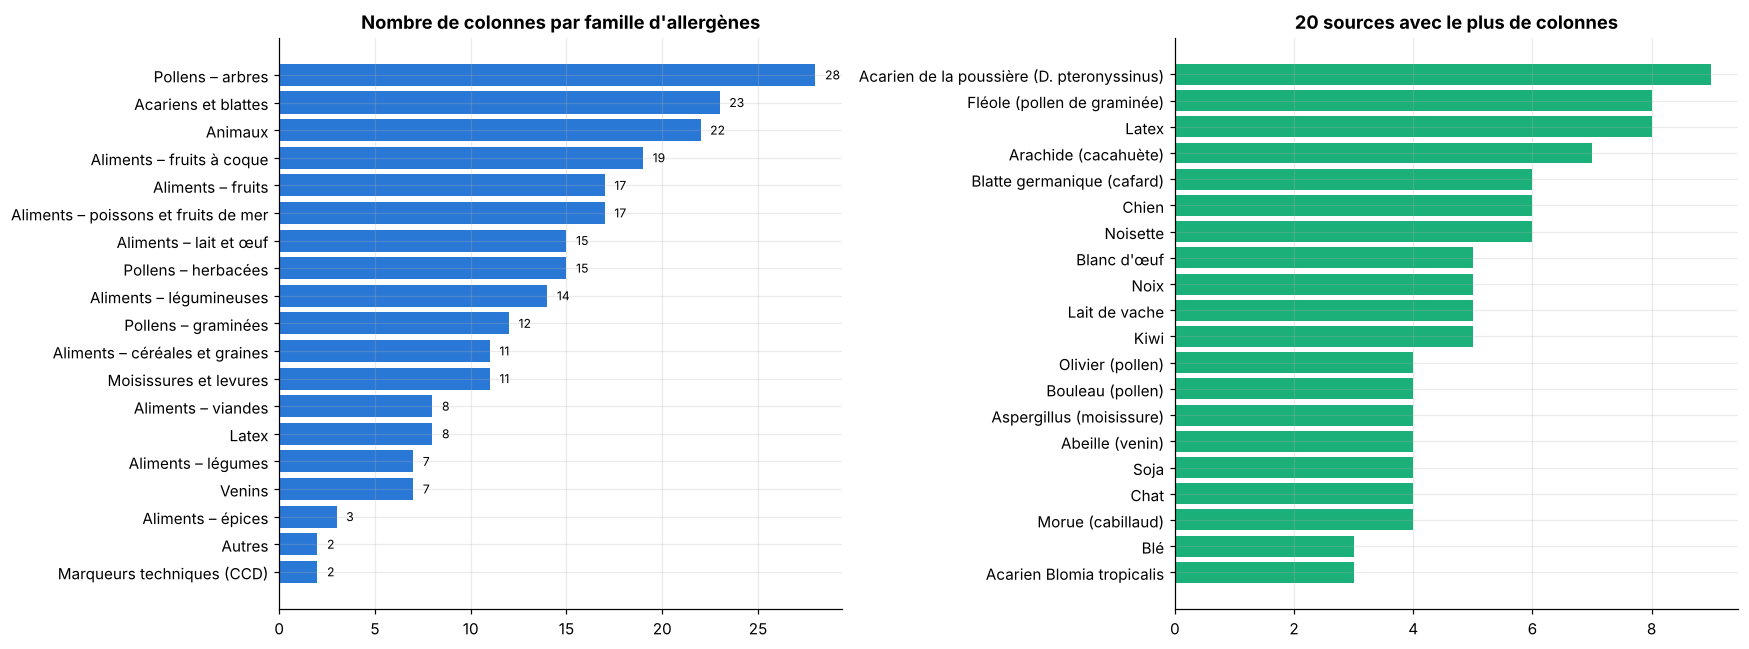

type
protéine (composant)    176
extrait complet          65


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
f = ige["famille"].value_counts().sort_values()
axes[0].barh(f.index, f.values, color=BLEU)
for i, v in enumerate(f.values): axes[0].text(v + 0.5, i, str(v), va="center", fontsize=8)
axes[0].set_title("Nombre de colonnes par famille d'allergènes")
s = ige["source"].value_counts().head(20).sort_values()
axes[1].barh(s.index, s.values, color="#1baf7a")
axes[1].set_title("20 sources avec le plus de colonnes")
plt.tight_layout(); plt.show()
print(ige["type"].value_counts().to_string())

**Interprétation**

- Les **aliments** sont de loin la plus grande famille (une centaine de colonnes), puis les pollens, les animaux et les acariens/blattes.
- Ces familles serviront à construire des variables simples (« sensibilisé à un pollen », « à un aliment »…) pour la suite.

### 4.2 Que contient une case d'IgE ?

**Ce que fait ce code :** compte les cases vides, les zéros, les valeurs entre 0 et 0,3, les valeurs ≥ 0,3 et les valeurs impossibles (-1).

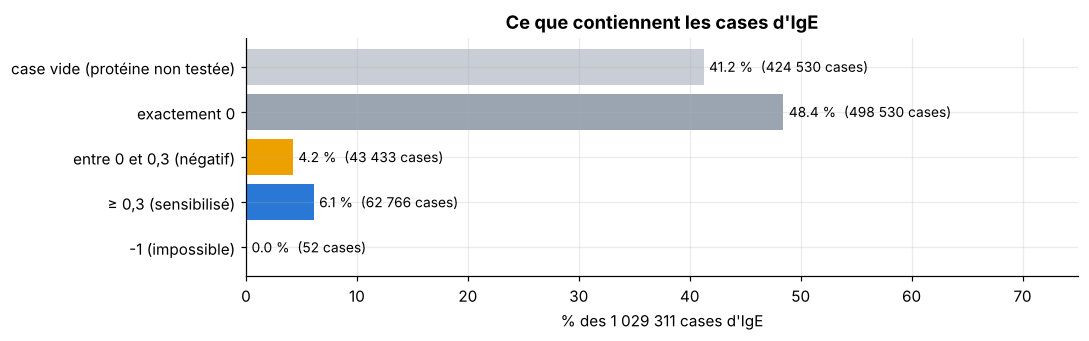

In [ ]:
X = df[COL_IGE].astype(float)
cat = pd.Series({
    "case vide (protéine non testée)": int(X.isna().sum().sum()),
    "exactement 0": int((X == 0).sum().sum()),
    "entre 0 et 0,3 (négatif)": int(((X > 0) & (X < 0.3)).sum().sum()),
    "≥ 0,3 (sensibilisé)": int((X >= 0.3).sum().sum()),
    "-1 (impossible)": int((X < 0).sum().sum()),
})
pct = cat / cat.sum() * 100
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.barh(pct.index, pct.values, color=[GRIS, "#9aa5b1", "#eda100", BLEU, ROUGE])
for i, (v, n) in enumerate(zip(pct.values, cat.values)): ax.text(v + 0.5, i, f"{v:.1f} %  ({n:,} cases)".replace(",", " "), va="center", fontsize=9)
ax.invert_yaxis(); ax.set_xlim(0, 75); ax.set_xlabel("% des 1 029 311 cases d'IgE")
ax.set_title("Ce que contiennent les cases d'IgE"); plt.tight_layout(); plt.show()

**Interprétation**

- **41 % des cases sont vides** : la protéine n'est pas testée par la puce du patient (ce n'est pas un oubli).
- 48 % valent exactement 0, 4 % sont entre 0 et 0,3 (négatif) et seulement **6 % sont positives (≥ 0,3)** : les données sont très creuses.
- **52 cases valent -1** : impossible pour un taux, à traiter comme manquantes.

### 4.3 Quelle puce teste quelle protéine ?

**Ce que fait ce code :** repère les protéines mesurées par chaque puce et celles communes aux trois, par famille.

Protéines testées par chaque puce : {'ISAC_V1': 112, 'ISAC_V2': 112, 'ALEX': 223}
Protéines testées par les 3 puces : 91


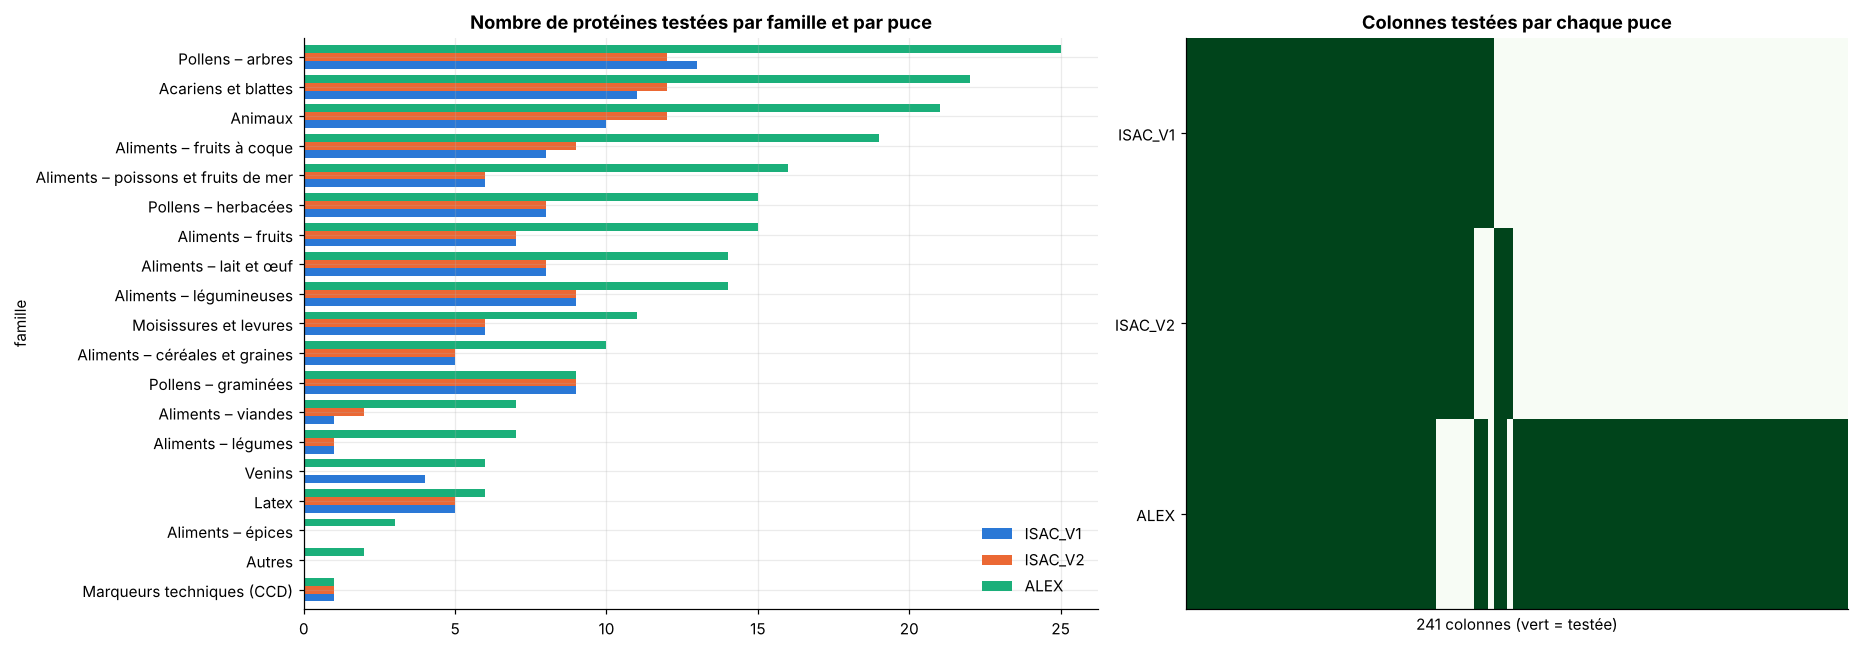

,ISAC_V1,ISAC_V2,ALEX,communes aux 3
famille,,,,
Marqueurs techniques (CCD),1,1,1,0
Autres,0,0,2,0
Aliments – épices,0,0,3,0
Latex,5,5,6,4
Venins,4,0,6,0
Aliments – légumes,1,1,7,1
Aliments – viandes,1,2,7,1
Pollens – graminées,9,9,9,6
Aliments – céréales et graines,5,5,10,4


In [ ]:
teste = X.notna().groupby(df["Chip_Type"]).mean().loc[PUCES] > 0.95      # True si la puce mesure la protéine
COMMUNS = list(teste.columns[teste.all()])
print("Protéines testées par chaque puce :", teste.sum(axis=1).to_dict())
print("Protéines testées par les 3 puces :", len(COMMUNS))

par_fam = pd.DataFrame({p: ige.loc[teste.columns[teste.loc[p]], "famille"].value_counts() for p in PUCES}).fillna(0).astype(int)
par_fam["communes aux 3"] = ige.loc[COMMUNS, "famille"].value_counts()
par_fam = par_fam.fillna(0).astype(int).sort_values("ALEX")
fig, axes = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [1.2, 1]})
par_fam[PUCES].plot(kind="barh", ax=axes[0], color=[COUL_PUCE[p] for p in PUCES], width=0.8)
axes[0].set_title("Nombre de protéines testées par famille et par puce"); axes[0].legend(frameon=False)
ordre_c = teste.T.sort_values(PUCES, ascending=False).index
axes[1].imshow(teste[ordre_c].values, aspect="auto", cmap="Greens", interpolation="nearest")
axes[1].set_yticks(range(3), PUCES); axes[1].set_xticks([]); axes[1].grid(False)
axes[1].set_xlabel("241 colonnes (vert = testée)"); axes[1].set_title("Colonnes testées par chaque puce")
plt.tight_layout(); plt.show()
display(par_fam)

**Interprétation**

- ALEX teste deux fois plus de protéines que les puces ISAC (223 contre 112).
- Seules **91 protéines sont communes aux 3 puces** : pour comparer tous les patients, il faudra se limiter à ces 91 colonnes.
- **Aucun venin n'est commun** aux 3 puces (ISAC_V2 n'en teste aucun) : les allergies aux venins sont hors de notre analyse commune.

### 4.4 Protéines les plus souvent positives

**Ce que fait ce code :** classe les 20 protéines avec le plus fort pourcentage de patients sensibilisés (≥ 0,3).

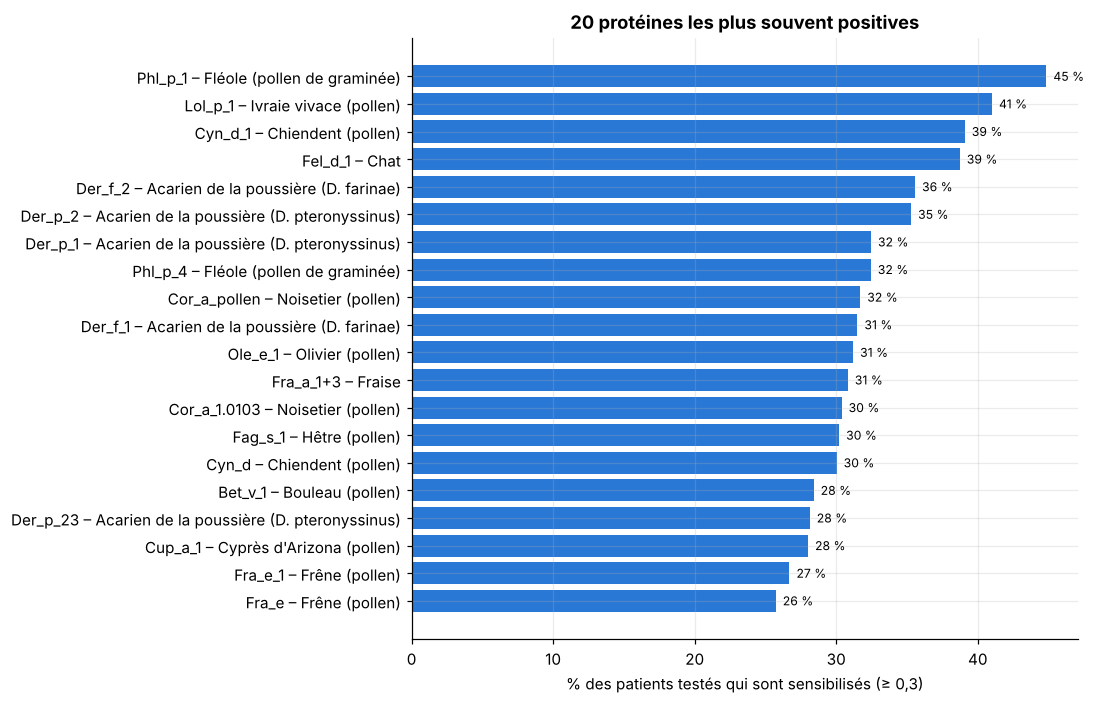

In [ ]:
prev = ((X >= 0.3).sum() / X.notna().sum() * 100).sort_values(ascending=False)
top = prev.head(20)[::-1]
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh([f"{c} – {ALLERGENES[c][0]}" for c in top.index], top.values, color=BLEU)
for i, v in enumerate(top.values): ax.text(v + 0.5, i, f"{v:.0f} %", va="center", fontsize=8)
ax.set_xlabel("% des patients testés qui sont sensibilisés (≥ 0,3)")
ax.set_title("20 protéines les plus souvent positives"); plt.tight_layout(); plt.show()

**Interprétation**

- Les plus fréquentes sont les **pollens de graminées** (Phl p 1, Lol p 1, Cyn d 1, 40 à 45 %), le **chat** (Fel d 1, 39 %) et les **acariens** (Der f 2, Der p 2, Der p 1, 32 à 36 %).
- Les allergènes respiratoires dominent chez les patients sensibilisés ; les aliments et les venins sont plus rares.

# 1.5 – Ce qu'on n'a pas dans le fichier

### 5. Colonnes absentes

**Ce que fait ce code :** vérifie que les colonnes de diagnostic décrites dans le dictionnaire PDF (allergie confirmée, allergie sévère…) ne sont pas dans le fichier.

In [ ]:
ABSENTES = ["Allergy_Present", "Severe_Allergy", "Respiratory_Allergy", "Food_Allergy", "Venom_Allergy",
            "Type_of_Respiratory_Allergy_ARIA", "Type_of_Respiratory_Allergy_GINA", "Type_of_Respiratory_Allergy_CONJ",
            "Type_of_Food_Allergy_Peanut", "Type_of_Food_Allergy_Egg", "Type_of_Food_Allergy_TPO", "Food_Type_0", "Food_Type_2"]
print("Colonnes décrites dans le dictionnaire PDF mais ABSENTES du fichier (exemples) :")
for c in ABSENTES: print(f"  - {c:45s} présente : {c in df.columns}")

Colonnes décrites dans le dictionnaire PDF mais ABSENTES du fichier (exemples) :
  - Allergy_Present                               présente : False
  - Severe_Allergy                                présente : False
  - Respiratory_Allergy                           présente : False
  - Food_Allergy                                  présente : False
  - Venom_Allergy                                 présente : False
  - Type_of_Respiratory_Allergy_ARIA              présente : False
  - Type_of_Respiratory_Allergy_GINA              présente : False
  - Type_of_Respiratory_Allergy_CONJ              présente : False
  - Type_of_Food_Allergy_Peanut                   présente : False
  - Type_of_Food_Allergy_Egg                      présente : False
  - Type_of_Food_Allergy_TPO                      présente : False
  - Food_Type_0                                   présente : False
  - Food_Type_2                                   présente : False


**Interprétation**

- Aucune colonne de **diagnostic** n'est présente : on ne sait pas directement qui est allergique ni qui a une allergie sévère.
- La sévérité ne peut être mesurée que **indirectement**, par le **niveau de traitement** de l'asthme, de la rhinite et de l'eczéma. Il n'y a pas de gravité pour les allergies alimentaires ni aux venins.
- Autres limites : seulement 91 protéines comparables entre puces ; informations cliniques absentes pour la moitié des patients ; régions et départements anonymisés.